<a href="https://colab.research.google.com/github/CienciaDatosUdea/002_EstudiantesAprendizajeEstadistico/blob/main/semestre2026-2/Laboratorios/Laboratorio_12_Lab_Hopfield.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



# **Laboratorio N°12: Memorias Asociativas con Redes de Hopfield**

**Curso:** Aprendizaje Estadistico 2026-2  
**Estudiante:** Jeronimo Lopez Gomez

---

## Objetivo

Construir una red de Hopfield capaz de almacenar imágenes binarias y recuperar una imagen original a partir de una versión con ruido.


# Actividades

Para las imágenes dadas, construya un algoritmo que permita recuperar la imagen original a partir de una imagen perturbada.

Debe implementar funciones para:

1. Convertir una imagen binaria en un vector de estados.
2. Calcular la matriz de pesos de Hopfield.
3. Calcular el campo local que siente una neurona.
4. Actualizar el estado de una neurona.
5. Calcular la energía total de la red.
6. Aplicar ruido a una imagen.
7. Recuperar la imagen mediante actualización asincrónica aleatoria.

---

# Modelo de Hopfield

La matriz de pesos se define mediante la regla de Hebb:

$$
w_{ij}=\frac{1}{N}\sum_{\mu=1}^{P}\xi_i^\mu \xi_j^\mu
$$

con:

$$
w_{ii}=0
$$

donde:

- $N$ es el número total de píxeles,
- $P$ es el número de patrones almacenados,
- $\xi^\mu$ es el patrón $\mu$-ésimo.

---

# Campo local

Para una neurona $i$, el campo local es:

$$
h_i=\sum_j w_{ij}s_j
$$

Este campo representa la influencia colectiva que todas las demás neuronas ejercen sobre la neurona $i$.

---

# Regla de actualización

La actualización determinista de Hopfield es:

$$
s_i \leftarrow \mathrm{sign}(h_i)
$$

Si:

$$
h_i>0
$$

entonces:

$$
s_i=1
$$

Si:

$$
h_i<0
$$

entonces:

$$
s_i=-1
$$

---

# Energía de la red

La energía total del sistema se define como:

$$
E(s)=-\frac{1}{2}\sum_{ij}w_{ij}s_is_j
$$

o equivalentemente:

$$
E(s)=-\frac{1}{2}s^TWs
$$

El proceso de recuperación debe tender a disminuir la energía.

---

# Algoritmo sugerido

Dada una imagen con ruido:

1. Seleccione aleatoriamente un píxel $i$.
2. Calcule el campo local:

$$
h_i=\sum_j w_{ij}s_j
$$

3. Actualice el estado del píxel:

$$
s_i \leftarrow \mathrm{sign}(h_i)
$$

4. Calcule la nueva energía del sistema:

$$
E(s)=-\frac{1}{2}s^TWs
$$

5. Visite otro píxel aleatoriamente.
6. Repita el proceso hasta que:
   - la imagen deje de cambiar,
   - la energía se estabilice,
   - o se alcance un número máximo de iteraciones.


# Comentario importante

La actualización debe ser preferiblemente **asincrónica y aleatoria**, porque cada vez que se actualiza un píxel, cambia el estado global de la red. Por tanto, el siguiente campo local debe calcularse usando la imagen ya actualizada.

---

# Preguntas guía

1. ¿La energía disminuye durante la recuperación?
2. ¿La red recupera exactamente la imagen original?
3. ¿Qué ocurre si aumenta el nivel de ruido?
4. ¿Qué pasa si se almacenan varias imágenes?
5. ¿Aparecen estados espurios?
6. ¿La recuperación depende del orden en que se actualizan los píxeles?
7. ¿Qué diferencia hay entre actualización sincrónica y asincrónica?

---

# Capacidad de memoria

La capacidad aproximada de una red de Hopfield clásica es:

$$
P_c \approx 0.138N
$$

donde:

- $P_c$ es el número máximo de patrones recuperables,
- $N$ es el número total de neuronas.

Cuando el número de patrones almacenados supera este valor, aparecen errores y estados espurios.

---

---




## **Desarrollo del laboratorio**

In [11]:
import numpy as np
import matplotlib.pyplot as plt

SEED=42

**Preparación de los datos proporcionados.** La función `patrones_balanceados` genera tres patrones: horizontal, vertical y tablero de ajedrez. Sus píxeles ya están representados como estados $-1$ y $+1$.

In [23]:
def patrones_balanceados(n, m):
    """ 
    Genera tres patrones balanceados de tamaño n x m: horizontal, vertical y ajedrez.
    Los patrones son matrices de 1 y -1.
    """
    horizontal = -np.ones((n, m))
    horizontal[:n//2, :] = 1

    vertical = -np.ones((n, m))
    vertical[:, :m//2] = 1

    checker = np.indices((n, m)).sum(axis=0)
    checker = np.where(checker % 2 == 0, 1, -1)

    return horizontal, vertical, checker

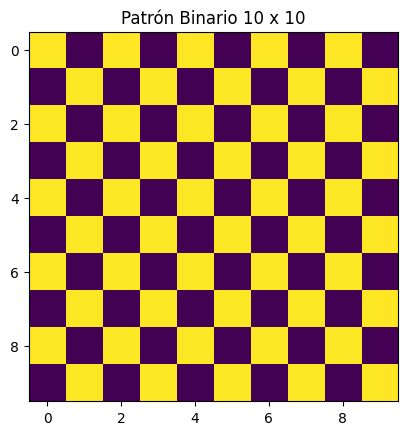

In [26]:
#Declaramos un patrón balanceado de tamaño 10x10
h, v, d = patrones_balanceados(10, 10)

plt.imshow(d)
plt.title(f"Patrón Binario {10} x {10}")
plt.show()

### 1. Conversión a vector de estados

La red necesita un estado por neurona. Por eso convertimos una imagen de dimensiones $n\times m$ en un vector $s$ de longitud $nm$, verificando que cada estado sea $-1$ o $+1$. Por ejemplo, una imagen $10\times10$ produce un vector de 100 componentes.

In [ ]:
#Declaramos una función para transformar la imagen binaria en un vector 1D

def imagen_a_vector(imagen):
    """Transforma una imagen binaria {-1, +1} en un vector 1D."""
    valores = np.asarray(imagen)
    if not np.all(np.isin(valores, [-1, 1])):
        raise ValueError("La imagen debe contener únicamente -1 y +1")
    return valores.reshape(-1).astype(np.int8)

original = imagen_a_vector(d)
print("Forma de la imagen:", d.shape)
print("Forma del vector:", original.shape)


Forma de la imagen: (10, 10)
Forma del vector: (100,)


### 2. Calcular la matriz de pesos de Hopfield

Implementamos la regla de Hebb, donde cada patrón almacenado aporta a las conexiones entre pares de neuronas. La diagonal se fija en cero. Guardaremos los tres patrones de $10\times10$, por lo que la matriz tendrá dimensiones $100\times100$.

In [16]:
#Definimos la función para calcular los pesos de la red de Hopfield
def calcular_pesos(patrones):
    """Calcula W mediante la regla de Hebb y anula su diagonal."""
    patrones = np.asarray(patrones, dtype=np.float32)
    if patrones.ndim == 1:
        patrones = patrones[None, :]
    P, N = patrones.shape
    W = (patrones.T @ patrones) / N
    np.fill_diagonal(W, 0)
    return W

patrones = [imagen_a_vector(p) for p in (h, v, d)]
W = calcular_pesos(patrones)
print("Número de patrones almacenados:", len(patrones))
print("Dimensiones de W:", W.shape)
print("¿Diagonal nula?:", np.all(np.diag(W) == 0))


Número de patrones almacenados: 3
Dimensiones de W: (100, 100)
¿Diagonal nula?: True


### 3. Calcular el campo local que siente una neurona

Para la neurona $i$, el campo local es $h_i=\sum_j w_{ij}s_j$. Es la suma de las influencias de las demás neuronas sobre el estado de la neurona objetivo.

In [19]:
def campo_local(W, s, i):
    """Calcula el valor del campo local que recibe la neurona i."""
    return float(W[i] @ s)

print("Campo local de la neurona 0 (h_0):", campo_local(W, original, 0))


Campo local de la neurona 0 (h_0): 0.9699999690055847


### 4. Actualizemos el estado de una neurona

Si $h_i>0$, el estado pasa a $+1$; si $h_i<0$, pasa a $-1$. **Si $h_i=0$**, conservamos el estado anterior para evitar una ambigüedad en `sign(0)`.

In [20]:
#Definimos la función para actualizar el estado de la neurona i
def actualizar_neurona(s, i, h_i):
    """Actualiza solo la neurona i; conserva su valor si h_i = 0."""
    if h_i > 0:
        s[i] = 1
    elif h_i < 0:
        s[i] = -1
    return s


### 5. Energía total de la red de Hopfield

La energía total esta expresada como

$$E(s)=-\frac{1}{2}s^TWs$$

In [27]:
def energia(W, s):
    """Energía de Hopfield: E = -1/2 s^T W s.
    W es la matriz de pesos y s es el vector de estado de la red.
    s es el vector de estado de la red."""
    return -0.5 * float(s @ (W @ s))

#Calculamos la energía del patrón original
print("Energía del patrón original:", energia(W, original))

Energía del patrón original: -48.499996185302734


### 6. Aplicar ruido a una imagen

`agregar_ruido(s, frac, seed)` selecciona aleatoriamente una fracción de los píxeles e invierte su signo ($+1\leftrightarrow-1$). Aquí el ruido del 25 % altera 25 de los 100 píxeles del patrón.

In [28]:
def agregar_ruido(s, frac=0.25, seed=None):
    """ 
    Agrega ruido a un patrón binario s, cambiando el signo de una fracción frac de sus elementos.
    """
    if seed is not None:
        np.random.seed(seed)

    s_ruido = s.copy()
    N = len(s)

    n_flip = int(frac * N)
    idx = np.random.choice(N, n_flip, replace=False)

    s_ruido[idx] *= -1

    return s_ruido

Píxeles modificados: 25 de 100


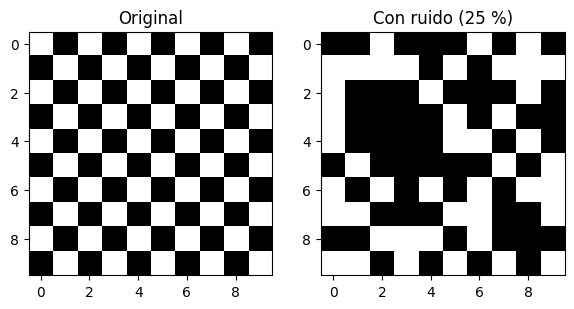

In [30]:
#Agregamos ruido al patrón generado
s_ruido = agregar_ruido(np.concat(d), frac=0.25, seed=SEED)

print("Píxeles modificados:", np.sum(s_ruido != np.concat(d)), "de", np.concat(d).size)

fig, ax = plt.subplots(1, 2, figsize=(6, 3))
for eje, patron, titulo in zip(ax, [original, s_ruido], ["Original", "Con ruido (25 %)"]):
    eje.imshow(patron.reshape(10, 10), cmap="gray", vmin=-1, vmax=1)
    eje.set_title(titulo)
plt.tight_layout()
plt.show()


### 7. Recuperación del Patrón Original

Se acceden a neuronas en **orden aleatorio** y se actualiza cada una antes de pasar a la siguiente. Se garantiza que se acceda a cada neurona una vez.

Para no recalcular una multiplicación matricial completa tras cada píxel, conservamos los campos locales en el vector `campos`. Cuando una neurona cambia, actualizamos inmediatamente esos campos, de modo que las siguientes neuronas utilizan el estado ya modificado. Registramos la energía al terminar cada barrido.

In [36]:
#Definimos la función para recuperar el patrón mediante barridos aleatorios asincrónicos
def recuperar_asincronica(W, s_inicial, original, max_barridos=30, seed=SEED):
    """Recupera un patrón mediante barridos aleatorios asincrónicos."""
    rng = np.random.default_rng(seed)
    s = np.asarray(s_inicial, dtype=np.int8).copy()
    N = s.size
    campos = W @ s.astype(np.float32)

    energias = [energia(W, s)]
    cambios = []
    coincidencias = [np.mean(s == original)]

    for _ in range(max_barridos):
        n_cambios = 0

        for i in rng.permutation(N):
            previo = int(s[i])
            #Utilizamos la función actualizar_neurona para actualizar el estado de la neurona i
            actualizar_neurona(s, i, campos[i])
            delta = int(s[i]) - previo

            if delta != 0:
                campos += delta * W[:, i]
                n_cambios += 1

        cambios.append(n_cambios)
        energias.append(-0.5 * float(s @ campos))

        # Registrar coincidencia después de cada barrido
        coincidencias.append(np.mean(s == original))

        if n_cambios == 0:
            break

    return s, np.array(energias), cambios, np.array(coincidencias)

Aplicamos las siete funciones al patrón de tablero. La gráfica de energía permite verificar si el algoritmo evoluciona hacia un estado estable.

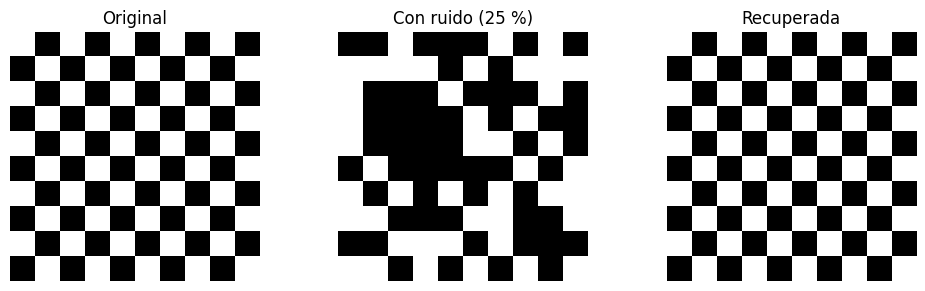

Coincidencia con la original: 100.00%
Cambios por barrido: [25, 0]
Cantidad de barridos realizados: 2


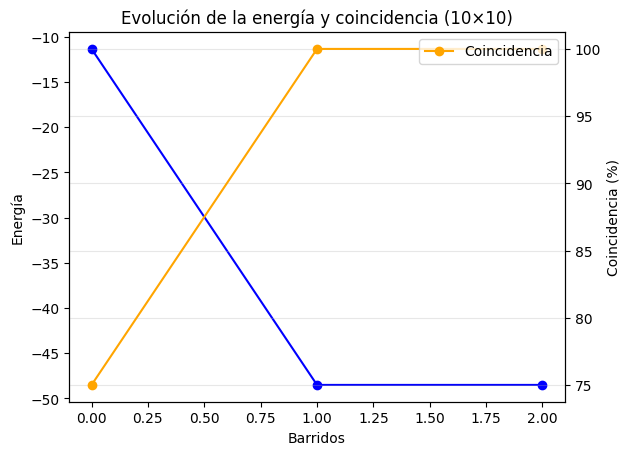

In [42]:
recuperada, energias, cambios, coincidencias = recuperar_asincronica(
    W, s_ruido, original, seed=SEED
)

fig, ax = plt.subplots(1, 3, figsize=(10, 3))

for eje, patron, titulo in zip(
    ax,
    [original, s_ruido, recuperada],
    ["Original", "Con ruido (25 %)", "Recuperada"]
):
    eje.imshow(patron.reshape(10, 10), cmap="gray", vmin=-1, vmax=1)
    eje.set_title(titulo)
    eje.axis("off")

plt.tight_layout()
plt.show()

print(f"Coincidencia con la original: {np.mean(original == recuperada):.2%}")
print("Cambios por barrido:", cambios)
print("Cantidad de barridos realizados:", len(energias) - 1)

# Evolución de la energía y la coincidencia
plt.plot(range(len(energias)), energias, marker="o", color="blue", label="Energía")
plt.xlabel("Barridos")
plt.ylabel("Energía")

# Graficamos la evolución de la coincidencia
ax_coincidencia = plt.twinx()
ax_coincidencia.set_ylabel("Coincidencia (%)")
ax_coincidencia.plot(range(len(coincidencias)), coincidencias * 100, marker="o", color="orange", label="Coincidencia")

plt.title("Evolución de la energía y coincidencia (10×10)")

plt.grid(alpha=0.3)
plt.legend(loc='upper right')
plt.show()

Analizemos que pasa si variamos el ruido

Comparamos cuatro niveles de ruido (10 %, 25 %, 40 % y 50 %) y dos condiciones: almacenar solo el tablero o almacenar los tres patrones. La coincidencia impresa en cada resultado se calcula respecto al patrón original. Estos resultados ayudan a observar posibles fallos de recuperación, sin asumir que todos los patrones o niveles de ruido se comportan igual.

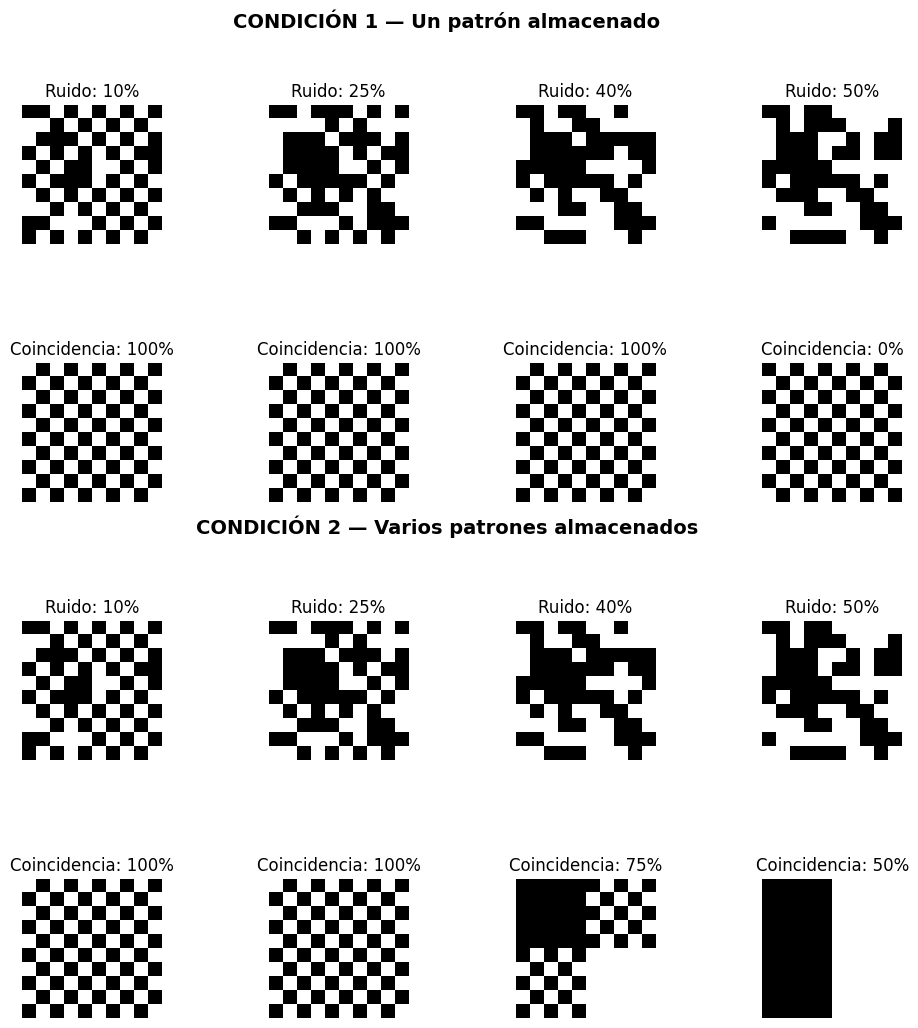

In [47]:
niveles_ruido = [0.10, 0.25, 0.40, 0.50]

fig, ax = plt.subplots(4, len(niveles_ruido), figsize=(12, 11))

condiciones = [
    ("Condición 1: Un patrón almacenado", [original]),
    ("Condición 2: Varios patrones almacenados", patrones)
]

for fila, (nombre_condicion, conjunto) in enumerate(condiciones):
    W_prueba = calcular_pesos(conjunto)

    for columna, fraccion in enumerate(niveles_ruido):
        alterada = agregar_ruido(original, frac=fraccion, seed=SEED)

        resultado, energias, cambios, coincidencias = recuperar_asincronica(
            W_prueba, alterada, original, seed=SEED
        )

        # Imagen con ruido
        ax[2*fila, columna].imshow(
            alterada.reshape(10, 10),
            cmap="gray", vmin=-1, vmax=1
        )
        ax[2*fila, columna].set_title(f"Ruido: {fraccion:.0%}")
        ax[2*fila, columna].axis("off")

        # Imagen recuperada
        ax[2*fila + 1, columna].imshow(
            resultado.reshape(10, 10),
            cmap="gray", vmin=-1, vmax=1
        )
        ax[2*fila + 1, columna].set_title(
            f"Coincidencia: {coincidencias[-1]:.0%}"
        )
        ax[2*fila + 1, columna].axis("off")

    # Etiquetas de cada fila
    ax[2*fila, 0].set_ylabel(
        "Con ruido", fontsize=11, labelpad=12
    )
    ax[2*fila + 1, 0].set_ylabel(
        "Recuperada", fontsize=11, labelpad=12
    )

# Títulos de las condiciones
fig.text(
    0.5, 0.95,
    "CONDICIÓN 1 — Un patrón almacenado",
    ha="center", fontsize=14, fontweight="bold"
)

fig.text(
    0.5, 0.49,
    "CONDICIÓN 2 — Varios patrones almacenados",
    ha="center", fontsize=14, fontweight="bold"
)

plt.subplots_adjust(
    top=0.88, bottom=0.05, hspace=0.85, wspace=0.3
)
plt.show()

## Hagamos ahora la recuperación de una imagen de 64 x 64

Se reduce de $512\times512$ una imagen de referencia a $64\times64$, se binariza alrededor del valor medio y se le aplica un ruido del 30 %. Después aplicamos nuestras funciones implementadas

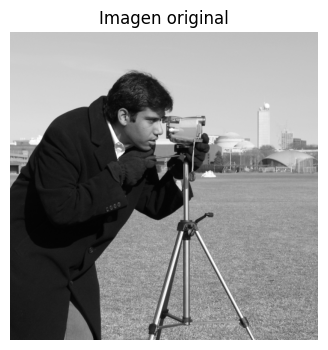

In [48]:
from skimage import data
from skimage.transform import resize
from skimage.color import rgb2gray

img = data.camera()   # imagen 512x512 en escala de grises

plt.figure(figsize=(4,4))
plt.imshow(img, cmap="gray")
plt.title("Imagen original")
plt.axis("off")
plt.show()

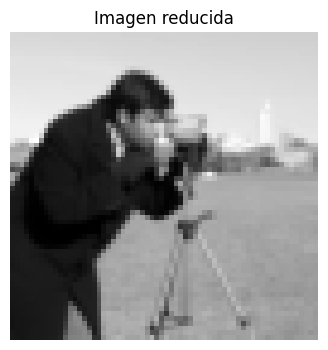

In [49]:
#Realizamos un resize de la imagen a 64x64 píxeles
n = 64
m = 64

img_small = resize(img, (n, m), anti_aliasing=True)

plt.figure(figsize=(4,4))
plt.imshow(img_small, cmap="gray")
plt.title("Imagen reducida")
plt.axis("off")
plt.show()

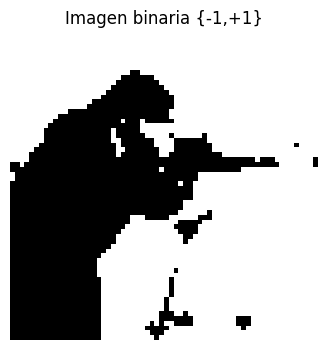

In [50]:
#Realizamos el proceso de binarización de la imagen reducida

threshold = img_small.mean()

img_bin = np.where(img_small > threshold, 1, -1)

plt.figure(figsize=(4,4))
plt.imshow(img_bin, cmap="gray")
plt.title("Imagen binaria {-1,+1}")
plt.axis("off")
plt.show()

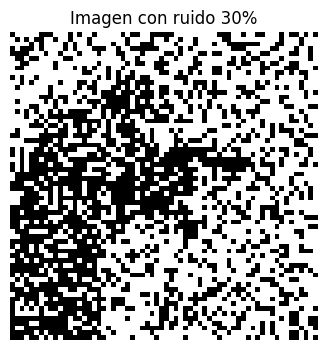

In [53]:
#Aplicamos la función agregar_ruido a la imagen binaria para introducir ruido en ella

frac_ruido = 0.30
s_ruido = agregar_ruido(np.concat(img_bin), frac=frac_ruido, seed=SEED)

plt.figure(figsize=(4,4))
plt.imshow(s_ruido.reshape(n, m), cmap="gray")
plt.title(f"Imagen con ruido {frac_ruido*100:.0f}%")
plt.axis("off")
plt.show()

la imagen tiene $N=64\times64=4096$ neuronas. Al almacenar un solo patrón, `calcular_pesos` produce una matriz de $4096\times4096$.

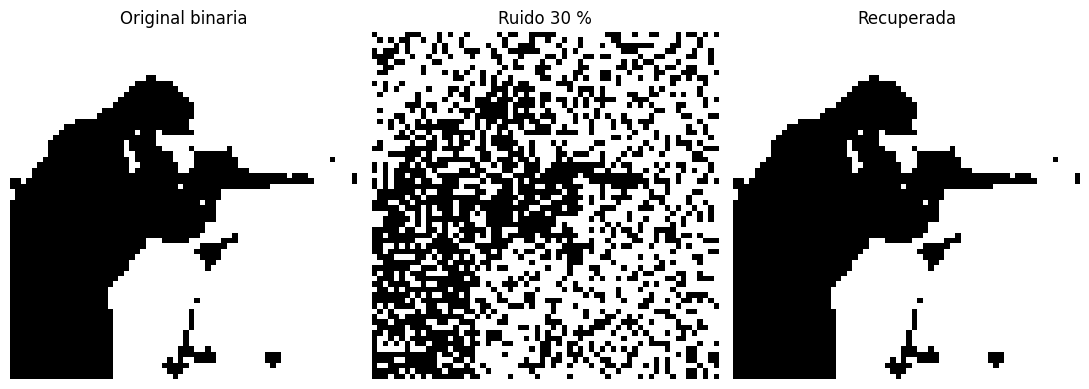

Coincidencia con la original: 100.00%
Cambios por barrido: [1228, 0]
Cantidad de barridos: 2


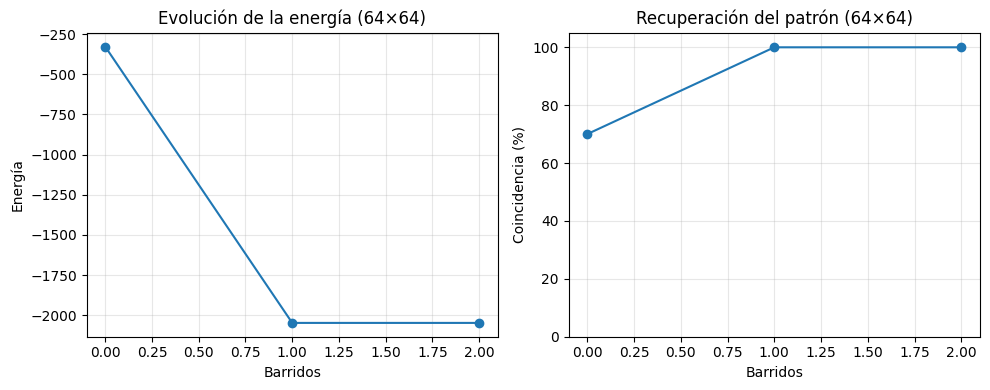

In [55]:
# Realizamos la conversión a vector de estados
patron_camara = imagen_a_vector(img_bin)

# Calculamos los pesos de la red de Hopfield para el patrón de la cámara
W_camara = calcular_pesos([patron_camara])

# Realizamos la recuperación del patrón de la cámara a partir de la imagen con ruido
recuperada_camara, energia_camara, cambios_camara, coincidencias_camara = recuperar_asincronica(
    W_camara, s_ruido, patron_camara, max_barridos=20, seed=SEED
)

# Visualizamos los patrones
fig, ax = plt.subplots(1, 3, figsize=(11, 4))

for eje, patron, titulo in zip(
    ax,
    [patron_camara, s_ruido, recuperada_camara],
    ["Original binaria", "Ruido 30 %", "Recuperada"]
):
    eje.imshow(patron.reshape(n, m), cmap="gray", vmin=-1, vmax=1)
    eje.set_title(titulo)
    eje.axis("off")

plt.tight_layout()
plt.show()

print(f"Coincidencia con la original: {coincidencias_camara[-1]:.2%}")
print("Cambios por barrido:", cambios_camara)
print("Cantidad de barridos:", len(energia_camara) - 1)

# Graficamos la evolución de la energía y la coincidencia
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

# Evolución de la energía
ax[0].plot(range(len(energia_camara)), energia_camara, marker="o")
ax[0].set_xlabel("Barridos")
ax[0].set_ylabel("Energía")
ax[0].set_title("Evolución de la energía (64×64)")
ax[0].grid(alpha=0.3)

# Evolución de la coincidencia
ax[1].plot(
    range(len(coincidencias_camara)),
    coincidencias_camara * 100,
    marker="o"
)
ax[1].set_xlabel("Barridos")
ax[1].set_ylabel("Coincidencia (%)")
ax[1].set_title("Recuperación del patrón (64×64)")
ax[1].set_ylim(0, 105)
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [58]:
W_orden = calcular_pesos(patrones)
estado_inicial = agregar_ruido(original, frac=0.40, seed=10)

# Recuperación con diferentes semillas
final_a, energia_a, cambios_a, coincidencias_a = recuperar_asincronica(
    W_orden, estado_inicial, original, seed=1
)

final_b, energia_b, cambios_b, coincidencias_b = recuperar_asincronica(
    W_orden, estado_inicial, original, seed=2
)

print(f"Semilla 1: coincidencia {coincidencias_a[-1]:.2%}")
print(f"Semilla 2: coincidencia {coincidencias_b[-1]:.2%}")
print("¿Mismo estado final?:", np.array_equal(final_a, final_b))
print("¿Misma evolución de energía?:", np.array_equal(energia_a, energia_b))

Semilla 1: coincidencia 50.00%
Semilla 2: coincidencia 50.00%
¿Mismo estado final?: True
¿Misma evolución de energía?: True


## Preguntas Guia

1. **¿La energía disminuye durante la recuperación?** Si, efectivamente la energía disminuye en el proceso de reuperación asincrónica.

2. **¿Se recupera exactamente la imagen original?** Al comparar las imágenes y el porcentaje de coincidencia mostrado. Para estas imagenes despues de realizar el proceso de binarización se obtiene un coincidencia del 100% excepto en casos como los que se describen en la siguientes preguntas.

3. **¿Qué ocurre si aumenta el nivel de ruido?** Al aumentar el nivel de ruido, la red tiene mayores dificultades para recuperar el patrón original. En la condición de un solo patrón almacenado, se obtuvo una coincidencia del 100 % para niveles de ruido del 10 %, 25 % y 40 %. Sin embargo, al aumentar el ruido al 50 %, la coincidencia disminuyó al 0 %, indicando que la red convergió hacia un patrón diferente al original.

4. **¿Qué pasa si se almacenan varias imágenes?** Al almacenar tres patrones, la red presentó mayores dificultades para recuperar la imagen original. Para niveles de ruido del 10 % y 25 %, la coincidencia fue del 100 %, pero disminuyó al 75 % con un ruido del 40 % y al 50 % con un ruido del 50 %.

En comparación con la red que almacena un solo patrón, estos resultados sugieren que la interferencia entre las memorias puede afectar la recuperación, especialmente cuando el ruido aumenta. Sin embargo, para el 50 % de ruido, la red con varios patrones obtuvo una coincidencia mayor que la red con uno solo.

5. **¿Aparecen estados espurios?** Con las gráficas obtenidas no podemos confirmar todavía la presencia de estados espurios. En la condición de un solo patrón almacenado, al aplicar un ruido del 50 %, la red recuperó un patrón invertido respecto al original, obteniendo una coincidencia del 0 %. Este comportamiento es compatible con la simetría de inversión de estados de la red de Hopfield, por lo que no constituye por sí solo evidencia de un estado espurio.

6. **¿La recuperación depende del orden de actualización?** Se realizaron dos ejecuciones con diferentes semillas aleatorias (seed=1 y seed=2), manteniendo el mismo patrón inicial con un 40 % de ruido y la misma matriz de pesos.
En ambos casos se obtuvo una coincidencia del 50 % con el patrón original. Además, las dos ejecuciones alcanzaron el mismo estado final y presentaron la misma evolución de energía. Estos resultados indican que, para las condiciones evaluadas, el cambio en el orden de actualización no afectó la recuperación del patrón

7. **¿Qué diferencia hay entre actualización sincrónica y asincrónica?** En la asincrónica se actualiza una neurona a la vez y se usa inmediatamente el nuevo estado; en la sincrónica se calculan todos los estados desde el mismo vector anterior.

Recuperamos el mismo patrón perturbado utilizando dos órdenes aleatorios distintos. Se compara el porcentaje de coincidencia y si el estado final es idéntico. Aunque los resultados finales coincidan, esto no implica que la secuencia de actualizaciones haya sido la misma.